In [30]:
import os
import sys
import warnings

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import PowerTransformer, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from scipy.stats import skew


sns.set_theme(style=("whitegrid"), palette="tab10")
warnings.filterwarnings("ignore")

In [31]:
df = pd.read_csv("housing.csv")

In [32]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [34]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [35]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [36]:
df["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [37]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')

In [38]:
columns = ['longitude', 'latitude', 'housing_median_age', 'total_rooms',
           'total_bedrooms', 'population', 'households', 'median_income',
           'median_house_value']

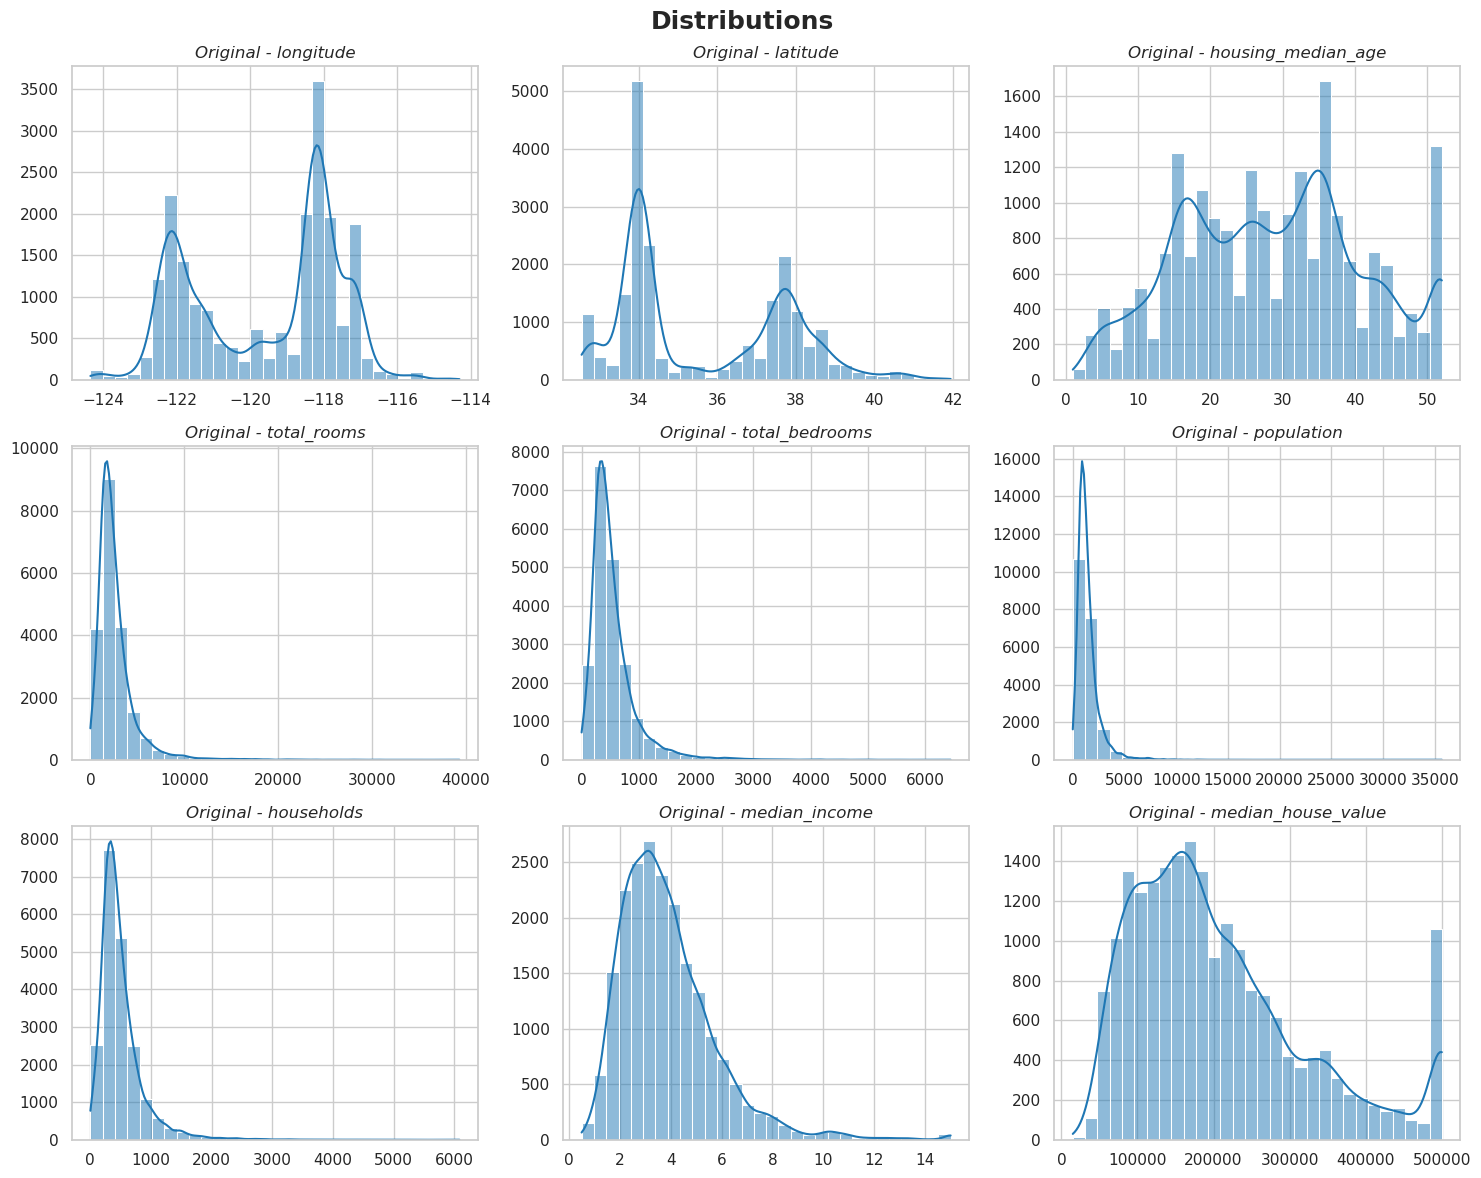

In [39]:
def plot_histograms(df, columns, title_prefix=""):

    fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15,12))
    plt.suptitle("Distributions", fontsize=18, fontweight = "bold")

    for i, col in enumerate(columns):
        row = i // 3 # 0, 0, 0, 1, 1, 1, 2, 2, 2...
        col_idx = i % 3 # 0, 1, 2, 0, 1, 2...
        ax = axes[row, col_idx] # dogru olan plotu seciyoruz
        sns.histplot(data=df, x=col, kde=True, ax=ax, bins=30)
        ax.set_title(f"{title_prefix} - {col}", fontsize=12, fontstyle="italic")
        ax.set_xlabel("")
        ax.set_ylabel("")
    
    plt.tight_layout()
    plt.show()

plot_histograms(df, columns, title_prefix="Original")

In [40]:
df.corr(numeric_only=True)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924664,-0.108197,0.044568,0.069608,0.099773,0.055310,-0.015176,-0.045967
latitude,-0.924664,1.000000,0.011173,-0.036100,-0.066983,-0.108785,-0.071035,-0.079809,-0.144160
housing_median_age,-0.108197,0.011173,1.000000,-0.361262,-0.320451,-0.296244,-0.302916,-0.119034,0.105623
total_rooms,0.044568,-0.036100,-0.361262,1.000000,0.930380,0.857126,0.918484,0.198050,0.134153
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686
population,0.099773,-0.108785,-0.296244,0.857126,0.877747,1.000000,0.907222,0.004834,-0.024650
households,0.055310,-0.071035,-0.302916,0.918484,0.979728,0.907222,1.000000,0.013033,0.065843
median_income,-0.015176,-0.079809,-0.119034,0.198050,-0.007723,0.004834,0.013033,1.000000,0.688075
median_house_value,-0.045967,-0.144160,0.105623,0.134153,0.049686,-0.024650,0.065843,0.688075,1.000000


In [41]:
df.select_dtypes("float64", "int").columns # istedigimiz turleri boyle alabiliriz.

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value'],
      dtype='object')

In [42]:
def find_outliers_iqr(df, threshold = 1.5):
    outlier_summary = {}
    
    numeric_cols = df.select_dtypes(include=["float64", "int64"]).columns

    for col in numeric_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - threshold * IQR
        upper_bound = Q3 + threshold * IQR

        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
        print(len(outliers))

        outlier_summary[col] = {
            "outlier_count" : outliers.shape[0],
            "outlier_percentange" : (outliers.shape[0] / df.shape[0]) * 100,
            "lower_bound" : lower_bound,
            "upper_bound" : upper_bound
        } 
    return pd.DataFrame(outlier_summary)

In [43]:
find_outliers_iqr(df)

0
0
0
1287
1271
1196
1220
681
1071


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
outlier_count,0.000,0.00,0.0,1287.000000,1271.000000,1196.000000,1220.000000,681.000000,1071.000000
outlier_percentange,0.000,0.00,0.0,6.235465,6.157946,5.794574,5.910853,3.299419,5.188953
lower_bound,-127.485,28.26,-10.5,-1102.625000,-230.500000,-620.000000,-207.500000,-0.706375,-98087.500000
upper_bound,-112.325,43.38,65.5,5698.375000,1173.500000,3132.000000,1092.500000,8.013025,482412.500000


In [44]:
def remove_outlier_from_column(df, target_col, threshold=1.5):
    df_clean = df.copy()
    
    Q1 = df_clean[target_col].quantile(0.25)
    Q3 = df_clean[target_col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - threshold * IQR
    upper_bound = Q3 + threshold * IQR
        
    df_clean = df[(df[target_col] >= lower_bound) & (df[target_col] <= upper_bound)]
    
    return df_clean.copy()

In [45]:
def remove_outliers_from_all_columns(df, threshold=1.5):
    df_clean = df.copy()
    numeric_cols = df.select_dtypes(include=["float64", "int64"]).columns
    
    for col in numeric_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
    
        lower_bound = Q1 - threshold * IQR
        upper_bound = Q3 + threshold * IQR

        df_claen = df_clean[(df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)]
    return df_clean.copy()

In [46]:
print("Original data shape: ", df.shape)

df_target_clean = remove_outlier_from_column(df, "median_house_value")
print("Only target columns cleaning shape: ", df_target_clean.shape)

df_all_clean = remove_outliers_from_all_columns(df)
print("all columns cleaning shape: ", df_all_clean.shape)

Original data shape:  (20640, 10)
Only target columns cleaning shape:  (19569, 10)
all columns cleaning shape:  (20640, 10)


In [47]:
df_target_clean.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,19569.000000,19569.000000,19569.000000,19569.000000,19369.000000,19569.000000,19569.000000,19569.000000,19569.000000
mean,-119.562786,35.654159,28.352752,2619.977260,539.893335,1442.788952,501.394859,3.665568,190852.301906
std,2.005764,2.151007,12.497772,2183.419302,422.650225,1145.011369,383.396308,1.557927,95438.555669
min,-124.350000,32.540000,1.000000,2.000000,2.000000,3.000000,2.000000,0.499900,14999.000000
25%,-121.760000,33.930000,18.000000,1438.000000,297.000000,797.000000,282.000000,2.522700,116200.000000
50%,-118.510000,34.270000,28.000000,2110.000000,437.000000,1181.000000,411.000000,3.441200,173200.000000
75%,-117.990000,37.730000,37.000000,3123.000000,648.000000,1749.000000,606.000000,4.572100,246700.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,482200.000000


In [48]:
df_target_clean.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        200
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [49]:
df_target_clean["total_bedrooms"] = df_target_clean["total_bedrooms"].fillna(df_target_clean["total_bedrooms"].median())

In [50]:
df_target_clean.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [51]:
df_target_clean.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,19569.000000,19569.000000,19569.000000,19569.000000,19569.000000,19569.000000,19569.000000,19569.000000,19569.000000
mean,-119.562786,35.654159,28.352752,2619.977260,538.841739,1442.788952,501.394859,3.665568,190852.301906
std,2.005764,2.151007,12.497772,2183.419302,420.612109,1145.011369,383.396308,1.557927,95438.555669
min,-124.350000,32.540000,1.000000,2.000000,2.000000,3.000000,2.000000,0.499900,14999.000000
25%,-121.760000,33.930000,18.000000,1438.000000,299.000000,797.000000,282.000000,2.522700,116200.000000
50%,-118.510000,34.270000,28.000000,2110.000000,437.000000,1181.000000,411.000000,3.441200,173200.000000
75%,-117.990000,37.730000,37.000000,3123.000000,645.000000,1749.000000,606.000000,4.572100,246700.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,482200.000000


In [52]:
df_target_clean.isnull().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

In [53]:
X = df_target_clean.drop("median_house_value", axis=1)
y = df_target_clean["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=42)

In [54]:
df_target_clean["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     8552
INLAND        6519
NEAR OCEAN    2419
NEAR BAY      2074
ISLAND           5
Name: count, dtype: int64

In [55]:
df_target_clean.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [57]:
num_cols = ['longitude', 'latitude', 'housing_median_age', 'total_rooms',
           'total_bedrooms', 'population', 'households', 'median_income']

numerical_pipeline = Pipeline([
    ("yeojohnson", PowerTransformer(method="yeo-johnson"))
])

In [58]:
preprocess = ColumnTransformer([
    ("num", numerical_pipeline, num_cols)
])

X_train_preprocessed = preprocess.fit_transform(X_train)
X_test_preprocessed = preprocess.transform(X_test) 

In [59]:
X_train_transformed_df = pd.DataFrame(X_train_preprocessed, columns=num_cols)
X_train_transformed_df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
0,8.604228e-16,-0.733169,0.478414,-0.505356,-0.277224,0.545841,-0.268773,-1.289369
1,-1.637579e-15,0.920666,-0.144523,-0.263567,0.315510,0.743852,0.247769,-0.279818
2,1.665335e-15,-1.721417,-0.064886,0.437528,0.831175,0.718348,0.893797,-0.790710
3,-1.193490e-15,1.265732,-1.065462,2.086734,1.903426,2.328350,2.055050,-0.459009
4,-4.163336e-16,-0.374312,-0.804722,0.326299,-0.228996,-0.277133,-0.225438,1.185254
...,...,...,...,...,...,...,...,...
13693,1.415534e-15,-0.790218,0.554224,-1.255635,-1.409166,-0.786085,-1.499154,0.373626
13694,-1.276756e-15,1.265732,-0.635345,1.633095,1.771033,1.205059,1.694642,-0.196100
13695,8.049117e-16,-0.920180,1.147129,-0.206541,0.214412,-0.064656,0.213992,-0.652673
13696,-1.526557e-15,0.952755,-0.386968,1.049621,1.008008,1.114619,1.072314,0.577481


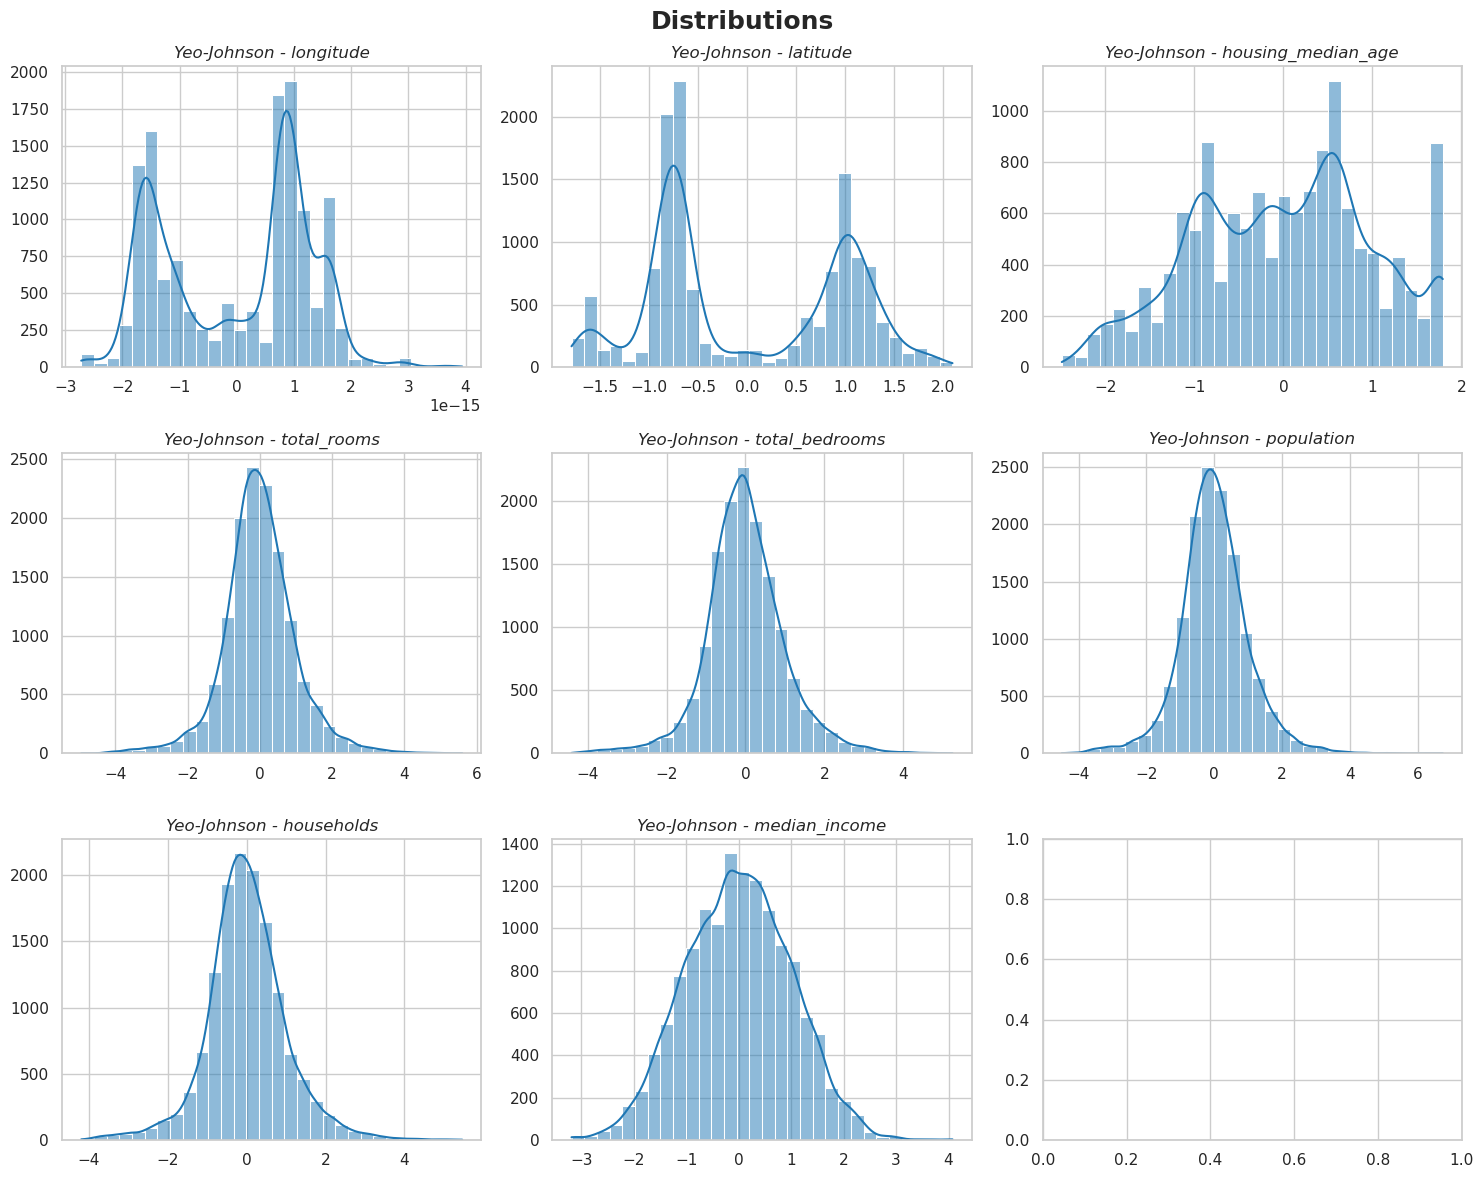

In [118]:
plot_histograms(X_train_transformed_df, num_cols, title_prefix="Yeo-Johnson")

In [119]:
df_target_clean = pd.get_dummies(data=df_target_clean, columns=["ocean_proximity"])

In [120]:
df_target_clean.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,False,False,False,True,False
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,False,False,False,True,False
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,False,False,False,True,False
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,False,False,False,True,False
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,False,False,False,True,False


In [121]:
df_target_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 19569 entries, 0 to 20639
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   longitude                   19569 non-null  float64
 1   latitude                    19569 non-null  float64
 2   housing_median_age          19569 non-null  float64
 3   total_rooms                 19569 non-null  float64
 4   total_bedrooms              19569 non-null  float64
 5   population                  19569 non-null  float64
 6   households                  19569 non-null  float64
 7   median_income               19569 non-null  float64
 8   median_house_value          19569 non-null  float64
 9   ocean_proximity_<1H OCEAN   19569 non-null  bool   
 10  ocean_proximity_INLAND      19569 non-null  bool   
 11  ocean_proximity_ISLAND      19569 non-null  bool   
 12  ocean_proximity_NEAR BAY    19569 non-null  bool   
 13  ocean_proximity_NEAR OCEAN  19569 no

In [35]:
bool_cols = ["ocean_proximity_<1H OCEAN","ocean_proximity_INLAND", "ocean_proximity_ISLAND", "ocean_proximity_NEAR BAY", "ocean_proximity_NEAR OCEAN"]

for col in bool_cols:
    df_target_clean[col] = df_target_clean[col].astype(int)

In [36]:
df_target_clean.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,0,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,0,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,0,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,0,0,0,1,0


In [37]:
df_target_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 19569 entries, 0 to 20639
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   longitude                   19569 non-null  float64
 1   latitude                    19569 non-null  float64
 2   housing_median_age          19569 non-null  float64
 3   total_rooms                 19569 non-null  float64
 4   total_bedrooms              19569 non-null  float64
 5   population                  19569 non-null  float64
 6   households                  19569 non-null  float64
 7   median_income               19569 non-null  float64
 8   median_house_value          19569 non-null  float64
 9   ocean_proximity_<1H OCEAN   19569 non-null  int64  
 10  ocean_proximity_INLAND      19569 non-null  int64  
 11  ocean_proximity_ISLAND      19569 non-null  int64  
 12  ocean_proximity_NEAR BAY    19569 non-null  int64  
 13  ocean_proximity_NEAR OCEAN  19569 no

In [38]:
df_target_clean[['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value']].apply(skew).sort_values(ascending=False)

population            4.961787
total_rooms           4.228578
total_bedrooms        3.479223
households            3.406650
median_income         0.889306
median_house_value    0.755894
latitude              0.455656
housing_median_age    0.070466
longitude            -0.289687
dtype: float64

In [39]:
def evaluate_model(true, predicted):
    mae = mean_absolute_error(true, predicted)
    mse = mean_squared_error(true, predicted)
    rmse = np.sqrt(mean_squared_error(true, predicted))
    r2_square = r2_score(true, predicted)

    return mae, rmse, r2_square

In [40]:
models = {
    "linear_regression" : LinearRegression(),
    "lasso" : Lasso(),
    "ridge" : Ridge(),
    "kneigbors_regressor" : KNeighborsRegressor(),
    "decisiontree_regression" : DecisionTreeRegressor(),
    "randomforest_regressor" : RandomForestRegressor(),
    "adaboost_regressor" : AdaBoostRegressor(),
    "gradientboosting_regressor" : GradientBoostingRegressor(),
    "xgboost_regressor" : XGBRegressor(),
    "lightgbm_regressor" : LGBMRegressor(verbosity=-1)
}

In [41]:
for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(X_train_preprocessed, y_train)

    y_train_pred = model.predict(X_train_preprocessed) # bu degerlere bakarak overfitting varmi kiyaslamasini yapabiliriz.
    y_test_pred = model.predict(X_test_preprocessed)   #

    model_train_mae, model_train_rmse, model_train_r2 = evaluate_model(y_train, y_train_pred)
    model_test_mae, model_test_rmse, model_test_r2 = evaluate_model(y_test, y_test_pred)

    print(list(models.keys())[i]) # hangi modelin yazdirildigini gormek icin.
    print("Model Performans for Traning Set")
    print("Root Mean Squared Error: ", model_train_rmse)
    print("Mean Absolute Error: ", model_train_mae)
    print("R2 Score: ", model_train_r2)

    print("-"*50)
    
    print("Model Performans for Test Set")
    print("Root Mean Squared Error: ", model_test_rmse)
    print("Mean Absolute Error: ", model_test_mae)
    print("R2 Score: ", model_test_r2)

    print("-"*50)
    print("\n")

linear_regression
Model Performans for Traning Set
Root Mean Squared Error:  66161.35619711566
Mean Absolute Error:  50414.148626641996
R2 Score:  0.5187180207430786
--------------------------------------------------
Model Performans for Test Set
Root Mean Squared Error:  64459.73427521666
Mean Absolute Error:  49564.5088275067
R2 Score:  0.545256492221678
--------------------------------------------------


lasso
Model Performans for Traning Set
Root Mean Squared Error:  66161.35696621594
Mean Absolute Error:  50414.347138376615
R2 Score:  0.5187180095536431
--------------------------------------------------
Model Performans for Test Set
Root Mean Squared Error:  64459.82951870879
Mean Absolute Error:  49564.895733527745
R2 Score:  0.54525514839387
--------------------------------------------------


ridge
Model Performans for Traning Set
Root Mean Squared Error:  66161.37177034473
Mean Absolute Error:  50415.0377544553
R2 Score:  0.5187177941722878
-----------------------------------

In [42]:
xgb = XGBRegressor()
xgb_params = {
        "n_estimators" : [100, 200, 300, 500],
        "learning_rate" : [0.01, 0.1],
        "max_depth" : [5, 8, 12, 20],
        "colsample_bytree" : [0.3, 0.4, 0.5, 0.6, 0.7, 1]
}

rscv = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=xgb_params,
    verbose=1,
    cv=5,
    n_jobs=-1
)

old_stderr = sys.stderr
sys.stderr = open(os.devnull, "w")

rscv.fit(X_train_preprocessed, y_train) # max_depth 20 -> will lead to overfitting

sys.stderr = old_stderr

y_train_pred1 = rscv.predict(X_train_preprocessed) # bu degerlere bakarak overfitting varmi kiyaslamasini yapabiliriz.
y_test_pred1 = rscv.predict(X_test_preprocessed)   

xgb_train_mae, xgb_train_rmse, xgb_train_r2 = evaluate_model(y_train, y_train_pred1)
xgb_test_mae, xgb_test_rmse, xgb_test_r2 = evaluate_model(y_test, y_test_pred1)

print("XGBResgressor")
print("Model Performans for Traning Set")
print("Root Mean Squared Error: ", xgb_train_rmse)
print("Mean Absolute Error: ", xgb_train_mae)
print("R2 Score: ", xgb_train_r2)

print("-"*50)
    
print("Model Performans for Test Set")
print("Root Mean Squared Error: ", xgb_test_rmse)
print("Mean Absolute Error: ", xgb_test_mae)
print("R2 Score: ", xgb_test_r2)

print("-"*50)
print("\n")

Fitting 5 folds for each of 10 candidates, totalling 50 fits
XGBResgressor
Model Performans for Traning Set
Root Mean Squared Error:  34553.99904967099
Mean Absolute Error:  24565.46273663354
R2 Score:  0.8687233647931073
--------------------------------------------------
Model Performans for Test Set
Root Mean Squared Error:  41802.52646360151
Mean Absolute Error:  29217.664041541582
R2 Score:  0.8087530372469287
--------------------------------------------------




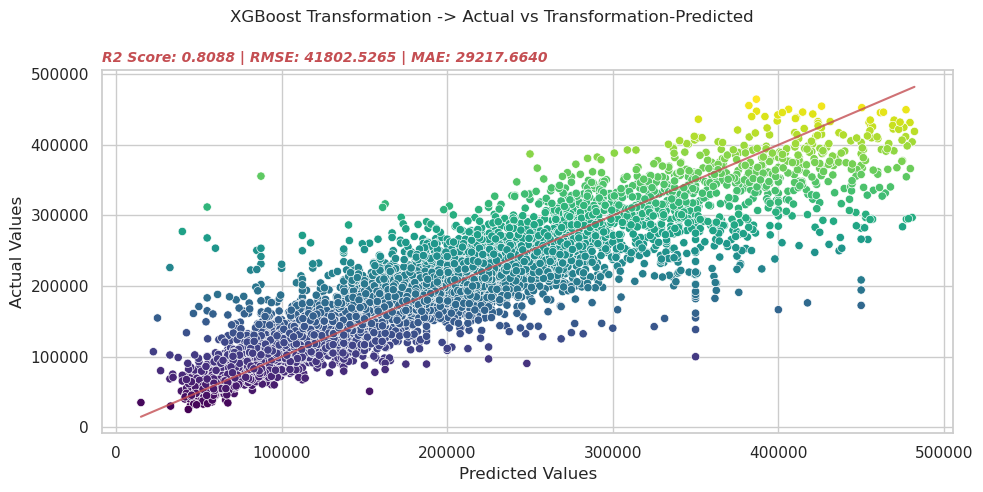

In [43]:
plt.figure(figsize=(10,5))
sns.set_theme(style=('whitegrid'))
sns.scatterplot(
    x = y_test,
    y = y_test_pred1,
    legend = False,
    hue = y_test_pred1,
    palette = "viridis"
)
plt.suptitle("XGBoost Transformation -> Actual vs Transformation-Predicted",fontsize = 12)

plt.title(f"R2 Score: {xgb_test_r2:.4f} | RMSE: {xgb_test_rmse:.4f} | MAE: {xgb_test_mae:.4f}", 
          fontsize=10, 
          loc='left', 
          style='italic', 
          fontweight="bold", 
          color="r"
)
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.plot([y_test.min(),y_test.max()], [y_test.min(), y_test.max()], linewidth=1.5, alpha=0.8, color = 'r')

plt.tight_layout()
plt.show()

In [44]:
lgbm_model = LGBMRegressor(verbosity=-1)
lgbm_params= {
        "learning_rate" : [0.01, 0.05, 0.1],
        "n_estimators" : [100, 300, 1000],
        "max_depth" : [-1, 5, 10], # max_depth (int, optional (default=-1)) -> limit yok demek
        "num_leaves" : [31, 50, 70],
        "min_child_samples" : [10, 20, 30],
        "subsample" : [0.6, 0.8, 1.0],
        "colsample_bytree" : [0.6, 0.8, 1.0],
        "reg_alpha" : [0, 0.5, 1.0],
        "reg_lambda" : [0, 0.5, 1.0]
}

rscv1 = RandomizedSearchCV(
    estimator=lgbm_model,
    param_distributions=lgbm_params,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    cv=5,
    n_jobs=-1
)

old_stderr = sys.stderr
sys.stderr = open(os.devnull, "w")

rscv1.fit(X_train_preprocessed, y_train) # max_depth 20 -> will lead to overfitting

sys.stderr = old_stderr

y_train_pred2 = rscv1.predict(X_train_preprocessed) # bu degerlere bakarak overfitting varmi kiyaslamasini yapabiliriz.
y_test_pred2 = rscv1.predict(X_test_preprocessed)   

lgbm_train_mae, lgbm_train_rmse, lgbm_train_r2 = evaluate_model(y_train, y_train_pred2)
lgbm_test_mae, lgbm_test_rmse, lgbm_test_r2 = evaluate_model(y_test, y_test_pred2)

print("LGBMRegressor")
print("Model Performans for Traning Set")
print("Root Mean Squared Error: ", lgbm_train_rmse)
print("Mean Absolute Error: ", lgbm_train_mae)
print("R2 Score: ", lgbm_train_r2)

print("-"*50)
    
print("Model Performans for Test Set")
print("Root Mean Squared Error: ", lgbm_test_rmse)
print("Mean Absolute Error: ", lgbm_test_mae)
print("R2 Score: ", lgbm_test_r2)

print("-"*50)
print("\n")

/home/yusuf/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/home/yusuf/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/home/yusuf/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/home/yusuf/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/home/yusuf/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


LGBMRegressor
Model Performans for Traning Set
Root Mean Squared Error:  29760.688635510327
Mean Absolute Error:  20925.87647981971
R2 Score:  0.9026184338052812
--------------------------------------------------
Model Performans for Test Set
Root Mean Squared Error:  40719.75002370003
Mean Absolute Error:  28170.970322894955
R2 Score:  0.8185321506676833
--------------------------------------------------




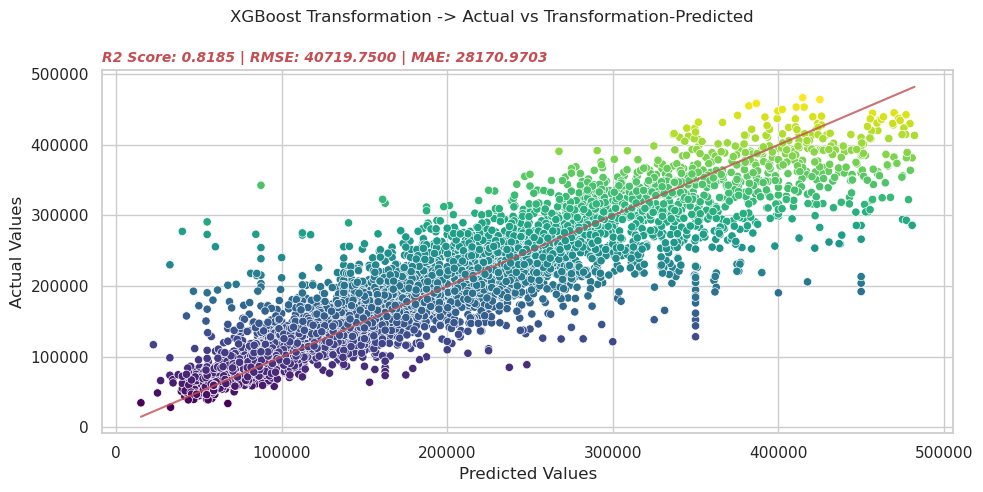

In [45]:
plt.figure(figsize=(10,5))
sns.set_theme(style=('whitegrid'))
sns.scatterplot(
    x = y_test,
    y = y_test_pred2,
    legend = False,
    hue = y_test_pred2,
    palette = "viridis"
)
plt.suptitle("XGBoost Transformation -> Actual vs Transformation-Predicted",fontsize = 12)

plt.title(f"R2 Score: {lgbm_test_r2:.4f} | RMSE: {lgbm_test_rmse:.4f} | MAE: {lgbm_test_mae:.4f}", 
          fontsize=10, 
          loc='left', 
          style='italic', 
          fontweight="bold", 
          color="r"
)
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.plot([y_test.min(),y_test.max()], [y_test.min(), y_test.max()], linewidth=1.5, alpha=0.8, color = 'r')

plt.tight_layout()
plt.show()